# Zdrowie publiczne a czynniki socjoekonomiczne w stanach USA (2013–2023)

**Cel:** sprawdzić, jak wskaźniki zdrowotne (otyłość, aktywność fizyczna) wiążą się z czynnikami społeczno-ekonomicznymi na poziomie stanów i czy stany da się pogrupować w sensowne typy.

**Dane** (szczegóły w `data/README.md`):
- **CDC BRFSS** – otyłość, aktywność fizyczna, dieta,
- **Census ACS 1-Year** – dochód, ubóstwo, wykształcenie, ubezpieczenie, dojazdy, praca z domu,
- **Census CBP** – liczba siłowni,
- **NOAA GSOM** – średnia temperatura.

Jednostka analizy: **50 stanów** (bez DC), lata 2013–2023 bez 2020 (brak ACS 1-Year). Do PCA i klasteryzacji każdy stan jest opisany średnią z dostępnych lat.

**Poprawki względem wersji z kursu** (w `src/ushealth/data.py`):
1. `pct_wyksztalcenie_wyzsze` dla 2013–2018 pochodzi z właściwego kodu ACS (`DP02_0067PE`; kody Data Profile przesuwają się między latami). Wcześniej te lata były usuwane.
2. `pct_bez_ubezpieczenia` = 100 − `DP03_0096PE` (oryginalna kolumna to odsetek **ubezpieczonych**).
3. Zmienione nazwy na zgodne z definicją: `pct_ubostwo_rodzin` (ubóstwo rodzin), `pct_bezrobotni` (bezrobotni jako % populacji 16+, a nie stopa bezrobocia).
4. Nazwy klastrów są wyznaczane z profili (ranking ryzyka R1 = najwyższe), a nie przypisane na sztywno do numerów klastrów.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

from ushealth.data import CLUSTER_COLS, LABELS, load_panel, state_profile
from ushealth import clustering as cl
from ushealth import plots

plots.setup()

## 1. Wczytanie danych i braki

In [2]:
panel = load_panel()
print(f"Panel: {panel.shape[0]} obserwacji (stan x rok), {panel['LocationAbbr'].nunique()} stanów")
print(f"Lata: {sorted(panel['Year'].unique())}")

Panel: 496 obserwacji (stan x rok), 50 stanów
Lata: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2021), np.int64(2022), np.int64(2023)]


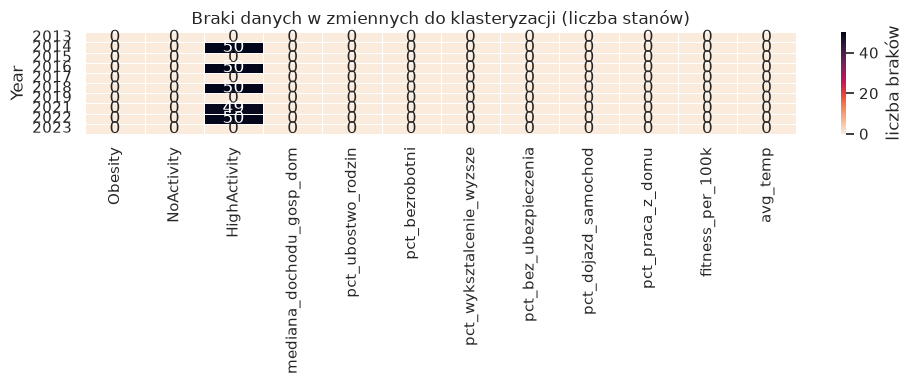

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(panel.groupby("Year")[CLUSTER_COLS].apply(lambda x: x.isna().sum()),
            cmap="rocket_r", linewidths=0.5, annot=True, fmt="d", ax=ax,
            cbar_kws={"label": "liczba braków"})
ax.set_title("Braki danych w zmiennych do klasteryzacji (liczba stanów)")
plt.tight_layout()
plt.show()

Jedyne braki dotyczą `HighActivity` – pytanie o wysoką aktywność fizyczną BRFSS zadaje tylko w latach nieparzystych. Średnia per stan dla tej zmiennej jest więc liczona z 5 lat, a dla pozostałych z 9–10.

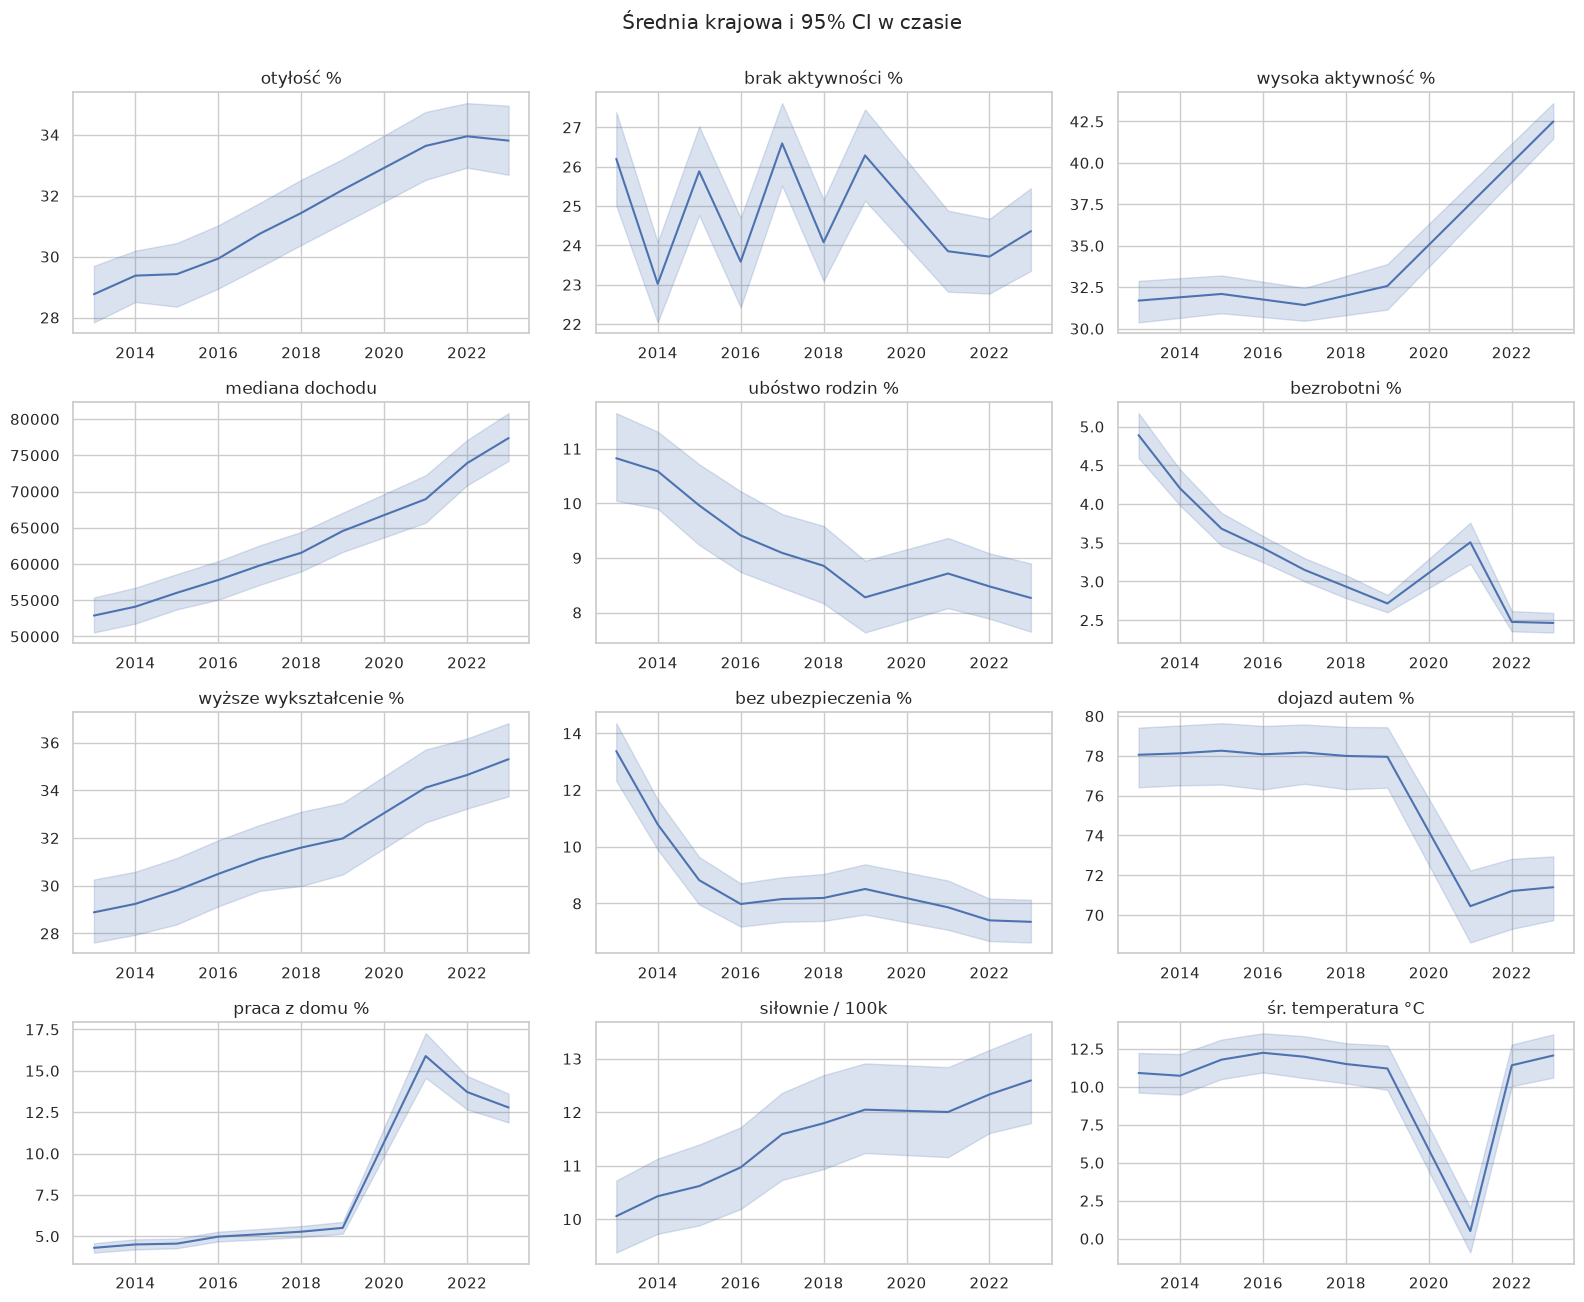

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(16, 13))
for ax, col in zip(axes.flat, CLUSTER_COLS):
    sns.lineplot(data=panel, x="Year", y=col, ax=ax)
    ax.set_title(LABELS[col])
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Średnia krajowa i 95% CI w czasie", y=1.0)
plt.tight_layout()
plt.show()

Widać skok pracy z domu i spadek dojazdów autem w 2021 (COVID) oraz spadek odsetka nieubezpieczonych po 2013 (ACA). Uśrednianie po latach łączy oba okresy – osobne porównanie jest w `03_porownanie_okresow.ipynb`.

In [5]:
states = state_profile(panel)
print(f"Stany: {len(states)}, braki po agregacji: {states[CLUSTER_COLS].isna().sum().sum()}")

Stany: 50, braki po agregacji: 0


## 2. Statystyki opisowe

In [6]:
desc = states[CLUSTER_COLS].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc.index = [LABELS[c] for c in desc.index]
desc.round(2)

,mean,std,min,25%,50%,75%,max
otyłość %,31.31,3.59,22.95,28.75,31.43,33.66,38.42
brak aktywności %,24.78,3.70,17.36,22.43,24.48,26.71,33.59
wysoka aktywność %,33.95,3.88,25.92,31.14,33.21,36.64,42.22
mediana dochodu,62612.23,10111.99,44966.60,55983.18,60447.40,70248.70,83587.40
ubóstwo rodzin %,9.26,2.48,4.76,7.33,8.61,10.78,15.60
bezrobotni %,3.35,0.62,1.88,2.83,3.44,3.77,4.49
wyższe wykształcenie %,31.70,5.21,21.40,28.43,31.00,34.66,43.96
bez ubezpieczenia %,8.85,3.00,2.84,6.53,8.59,10.75,17.93
dojazd autem %,75.99,5.69,51.75,73.45,77.28,80.23,84.21
praca z domu %,7.63,1.79,3.47,6.44,7.37,8.98,11.94


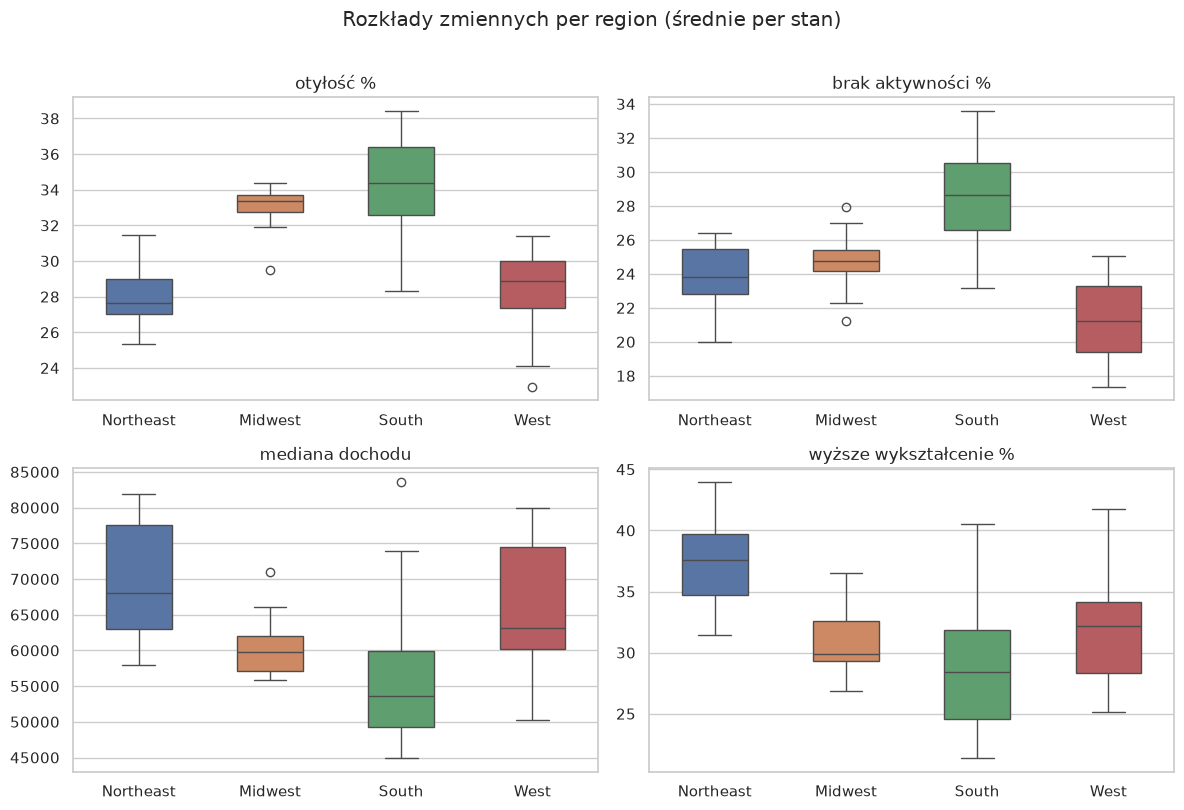

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["Obesity", "NoActivity", "mediana_dochodu_gosp_dom", "pct_wyksztalcenie_wyzsze"]):
    sns.boxplot(data=states, x="Region", y=col, hue="Region", order=list(plots.REGION_PALETTE),
                palette=plots.REGION_PALETTE, width=0.5, ax=ax, legend=False)
    ax.set_title(LABELS[col])
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Rozkłady zmiennych per region (średnie per stan)", y=1.01)
plt.tight_layout()
plots.save(fig, "02_boxplots_region")
plt.show()

Południe (South) ma najwyższą otyłość i brak aktywności przy najniższych dochodach i wykształceniu. Northeast jest po przeciwnej stronie pod względem dochodu i wykształcenia, ale najwyższą aktywność ma West. Midwest jest pośrodku, z małym zróżnicowaniem między stanami. Maryland jest wyraźnym outlierem Południa (wysoki dochód i wykształcenie).

## 3. Trend otyłości

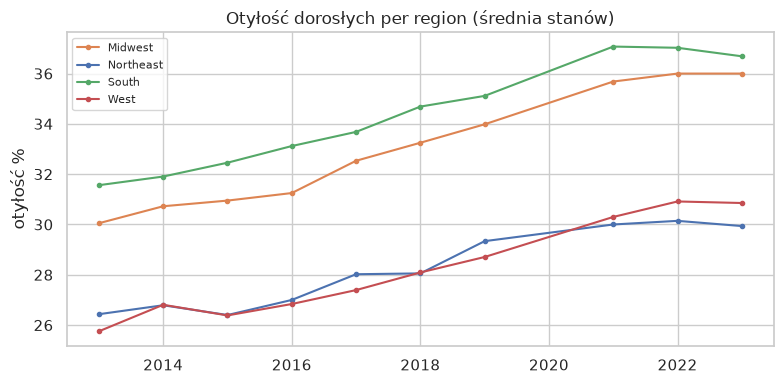

Region  Midwest  Northeast  South  West
Year                                   
2013       30.0       26.4   31.6  25.8
2023       36.0       29.9   36.7  30.9


In [8]:
trend = panel.groupby(["Year", "Region"])["Obesity"].mean().reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
for region, grp in trend.groupby("Region"):
    ax.plot(grp["Year"], grp["Obesity"], marker="o", ms=3, label=region, color=plots.REGION_PALETTE[region])
ax.set_title("Otyłość dorosłych per region (średnia stanów)")
ax.set_ylabel("otyłość %")
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax.legend(fontsize=8)
plt.tight_layout()
plots.save(fig, "03_obesity_trend")
plt.show()
print((trend.pivot(index="Year", columns="Region", values="Obesity").loc[[2013, 2023]]).round(1))

Otyłość rośnie we wszystkich regionach, a luka między Południem a resztą się nie zmniejsza. Spadek po 2022 to jeden punkt danych – za mało, żeby mówić o odwróceniu trendu.

## 4. Korelacje (Spearman, średnie per stan)

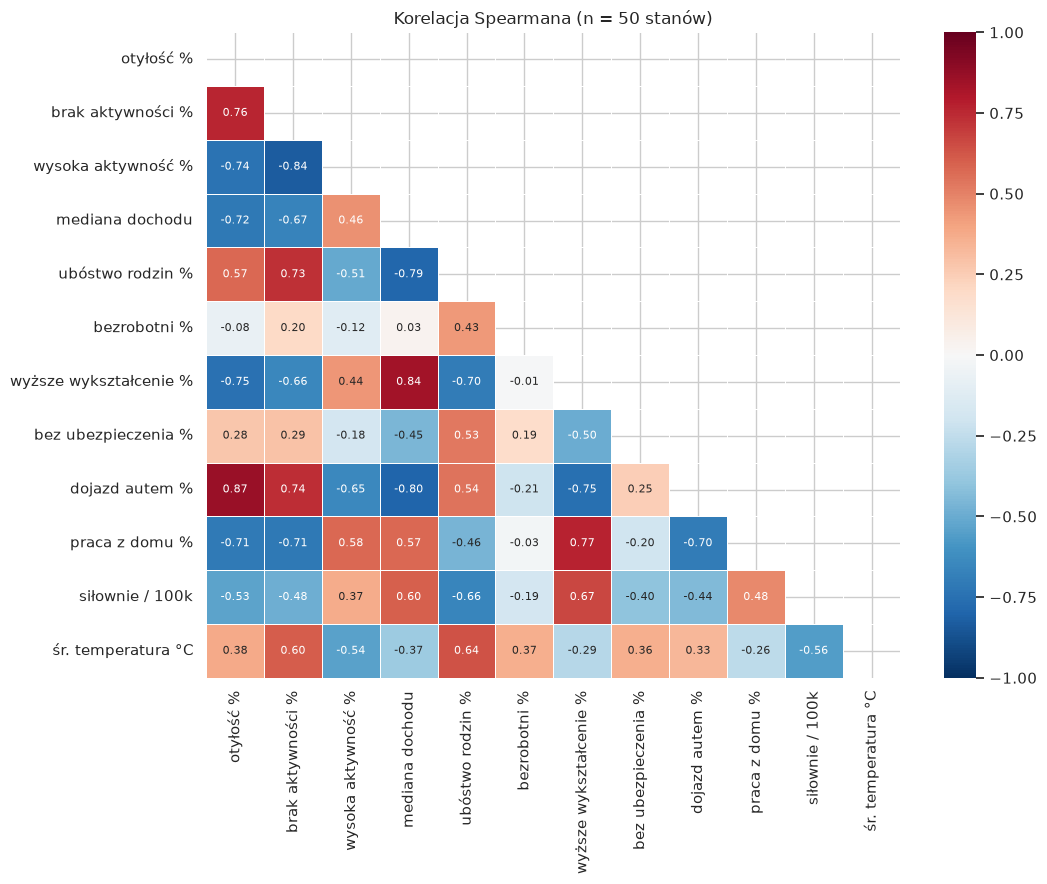

wyższe wykształcenie %   -0.75
wysoka aktywność %       -0.74
mediana dochodu          -0.72
praca z domu %           -0.71
siłownie / 100k          -0.53
bezrobotni %             -0.08
bez ubezpieczenia %       0.28
śr. temperatura °C        0.38
ubóstwo rodzin %          0.57
brak aktywności %         0.76
dojazd autem %            0.87
Name: Obesity, dtype: float64

In [9]:
corr = states[CLUSTER_COLS].corr(method="spearman")
corr_named = corr.rename(index=LABELS, columns=LABELS)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_named, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="RdBu_r",
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.4, ax=ax)
ax.set_title("Korelacja Spearmana (n = 50 stanów)")
plt.tight_layout()
plots.save(fig, "04_correlation")
plt.show()
corr["Obesity"].drop("Obesity").sort_values().rename(LABELS).round(2)

Korelacje są liczone na 50 stanach (dane zagregowane), więc opisują różnice **między stanami**, a nie zależności na poziomie osób (ryzyko błędu ekologicznego). Nie mówią też nic o przyczynowości – np. dojazd autem i niska praca z domu to raczej wskaźniki urbanizacji i struktury rynku pracy niż bezpośrednie przyczyny otyłości.

## 5. Kluczowe zależności

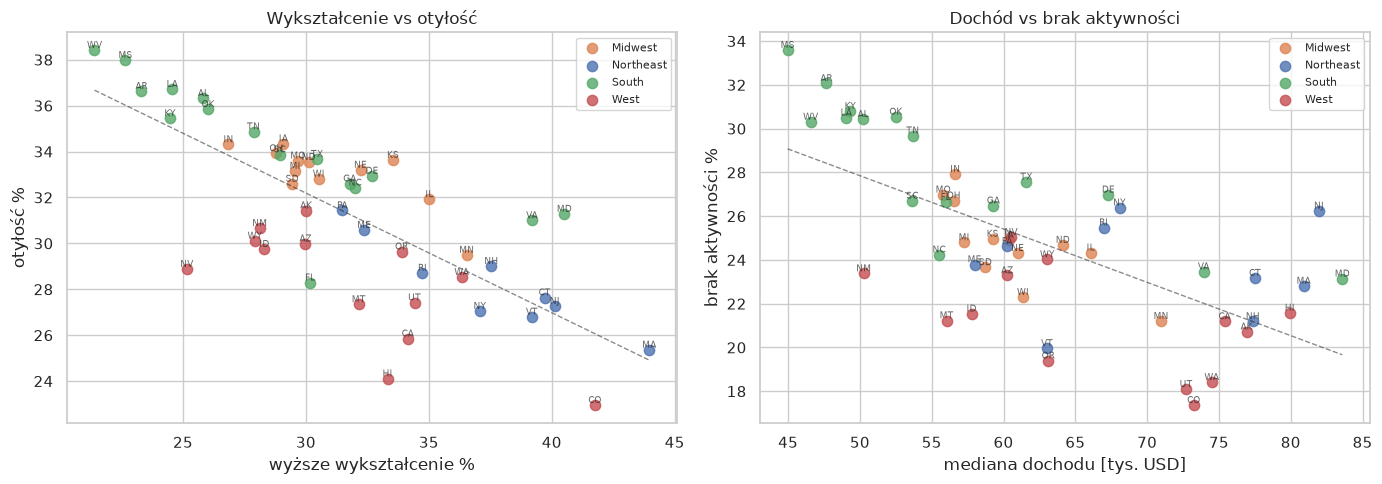

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pairs = [("pct_wyksztalcenie_wyzsze", "Obesity", 1), ("mediana_dochodu_gosp_dom", "NoActivity", 1000)]
for ax, (xcol, ycol, scale) in zip(axes, pairs):
    x = states[xcol] / scale
    for region, grp in states.groupby("Region"):
        ax.scatter(grp[xcol] / scale, grp[ycol], s=55, alpha=0.8, color=plots.REGION_PALETTE[region], label=region)
    for _, row in states.iterrows():
        ax.annotate(row["LocationAbbr"], (row[xcol] / scale, row[ycol]), fontsize=6.5, ha="center", va="bottom", alpha=0.7)
    m, b = np.polyfit(x, states[ycol], 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, m * xs + b, "k--", lw=1, alpha=0.5)
    ax.set_xlabel(LABELS[xcol] + (" [tys. USD]" if scale == 1000 else ""))
    ax.set_ylabel(LABELS[ycol])
    ax.legend(fontsize=8)
axes[0].set_title("Wykształcenie vs otyłość")
axes[1].set_title("Dochód vs brak aktywności")
plt.tight_layout()
plots.save(fig, "05_scatter")
plt.show()

Mississippi, West Virginia i Alabama są w lewym górnym rogu (mało absolwentów, dużo otyłości), Massachusetts, Colorado i Connecticut po prawej. Przy dochodzie wyróżniają się NJ i NY – wysokie dochody, ale relatywnie dużo nieaktywnych.

## 6. PCA

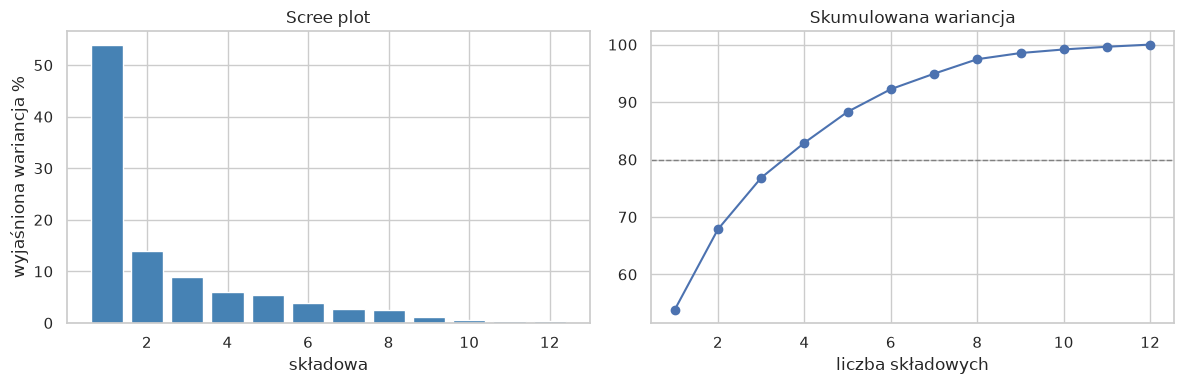

PC1: 53.9%, PC2: 14.0%, PC1+PC2: 67.9%, PC1-3: 76.8%


In [11]:
X_raw = states[CLUSTER_COLS].values
X_scaled, X_pca, pca = cl.fit_pca(X_raw)
X2 = X_pca[:, :2]
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(explained) + 1), explained * 100, color="steelblue")
axes[0].set_title("Scree plot")
axes[0].set_xlabel("składowa")
axes[0].set_ylabel("wyjaśniona wariancja %")
axes[1].plot(range(1, len(explained) + 1), np.cumsum(explained) * 100, "o-")
axes[1].axhline(80, ls="--", color="gray", lw=1)
axes[1].set_title("Skumulowana wariancja")
axes[1].set_xlabel("liczba składowych")
plt.tight_layout()
plots.save(fig, "06_pca_scree")
plt.show()
print(f"PC1: {explained[0]:.1%}, PC2: {explained[1]:.1%}, PC1+PC2: {explained[:2].sum():.1%}, PC1-3: {explained[:3].sum():.1%}")

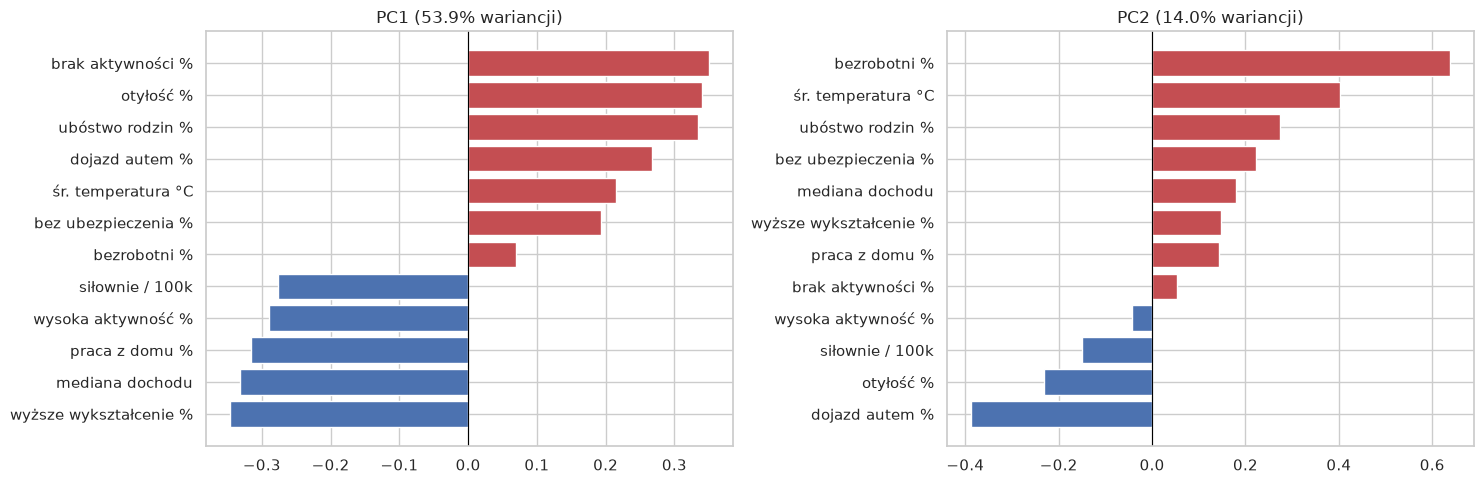

In [12]:
loadings = pd.DataFrame(pca.components_[:2].T, index=[LABELS[c] for c in CLUSTER_COLS], columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, pc, ev in zip(axes, ["PC1", "PC2"], explained):
    s = loadings[pc].sort_values()
    ax.barh(s.index, s.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in s])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{pc} ({ev:.1%} wariancji)")
plt.tight_layout()
plots.save(fig, "07_pca_loadings")
plt.show()

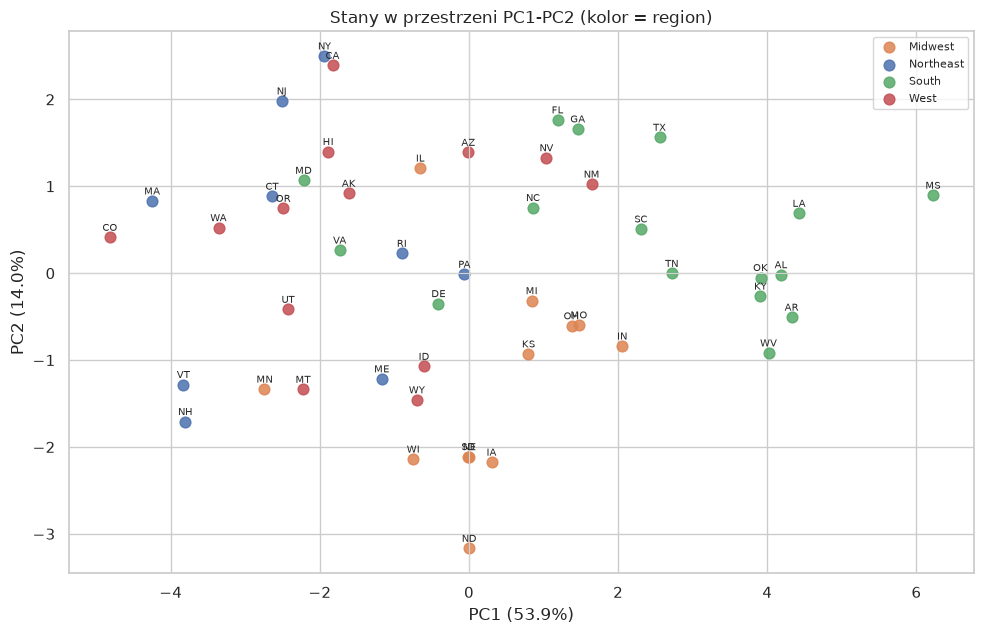

In [13]:
fig = plots.pca_scatter(states, X2, explained, states["Region"], plots.REGION_PALETTE, "Stany w przestrzeni PC1-PC2 (kolor = region)")
plots.save(fig, "08_pca_regions")
plt.show()

**PC1** to oś „zamożność–zdrowie”: po jednej stronie otyłość, brak aktywności, ubóstwo i dojazd autem, po drugiej wykształcenie, dochód, praca z domu i siłownie. **PC2** wyciąga stany ciepłe i z większymi miastami (FL, AZ, NV, TX) – temperatura, mniej dojazdów autem, więcej nieubezpieczonych. Northeast i West leżą po jednej stronie PC1, South po drugiej, Midwest rozciąga się pośrodku.

## 7. Klasteryzacja

Jak w wersji kursowej, klastrujemy w przestrzeni **PC1–PC2** (ok. 68% wariancji), co ułatwia wizualizację. Koszt tej decyzji jest oceniony w sekcji 9. Nazwy klastrów (`R1` = najwyższe ryzyko zdrowotne) są generowane z profili: ranking po średniej z-score zmiennych ryzyka i dwie cechy najbardziej odstające od średniej.

### 7.1 Hierarchiczna (Ward)

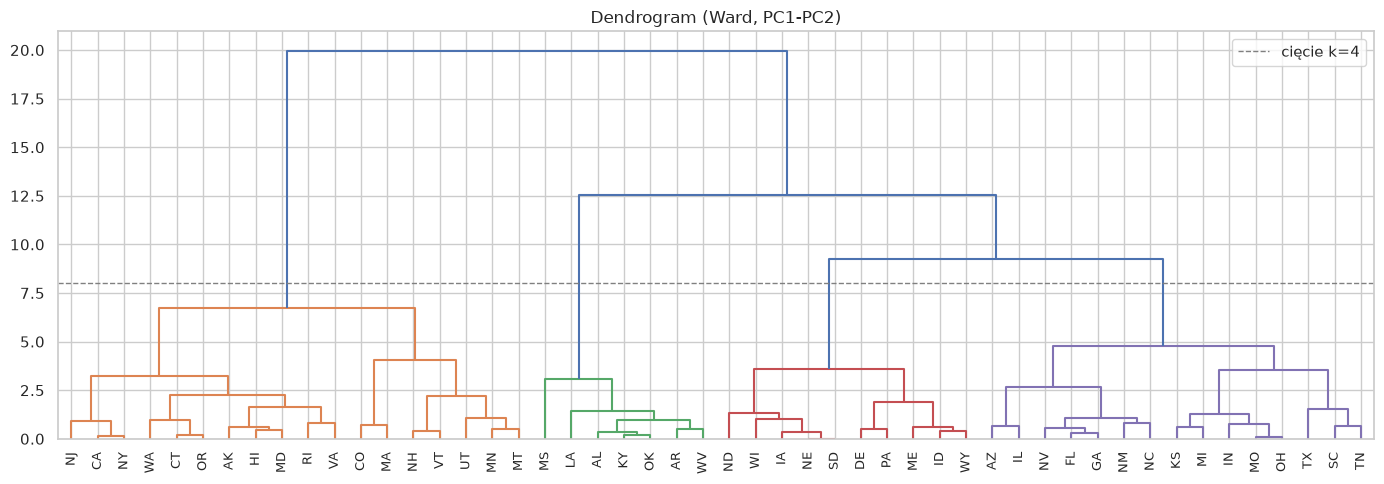

Wysokości 6 ostatnich połączeń: [ 4.04  4.79  6.71  9.27 12.53 19.96]


In [14]:
Z = linkage(X2, method="ward")
fig, ax = plt.subplots(figsize=(14, 5))
cut = (Z[-4, 2] + Z[-3, 2]) / 2
dendrogram(Z, labels=states["LocationAbbr"].values, leaf_font_size=9, color_threshold=cut, ax=ax)
ax.axhline(cut, ls="--", color="gray", lw=1, label="cięcie k=4")
ax.set_title("Dendrogram (Ward, PC1-PC2)")
ax.legend()
plt.tight_layout()
plots.save(fig, "09_dendrogram")
plt.show()
print("Wysokości 6 ostatnich połączeń:", Z[-6:, 2].round(2))

Największy skok wysokości połączeń jest przy przejściu z 2 do 1 klastra, kolejne (4→3, 3→2) są umiarkowane. Cięcie na k=4 jest decyzją interpretacyjną, a nie wynikającą jednoznacznie z dendrogramu.

In [15]:
labels_ward = cl.hierarchical(X2, 4)
names_ward = cl.cluster_names(states, labels_ward, CLUSTER_COLS)
print(cl.scores(X2, labels_ward))
for name, grp in states.groupby(names_ward):
    print(f"{name} ({len(grp)}): {', '.join(grp['LocationAbbr'])}")

{'silhouette': 0.40514332599799674, 'davies_bouldin': 0.7523446676690246, 'n_clusters': 4}
R1: brak aktywności ↑, ubóstwo rodzin ↑ (7): AL, AR, KY, LA, MS, OK, WV
R2: bez ubezpieczenia ↑, siłownie / 100k ↓ (15): AZ, FL, GA, IL, IN, KS, MI, MO, NV, NM, NC, OH, SC, TN, TX
R3: bezrobotni ↓, śr. temperatura °C ↓ (10): DE, ID, IA, ME, NE, ND, PA, SD, WI, WY
R4: mediana dochodu ↑, wyższe wykształcenie ↑ (18): AK, CA, CO, CT, HI, MD, MA, MN, MT, NH, NJ, NY, OR, RI, UT, VT, VA, WA


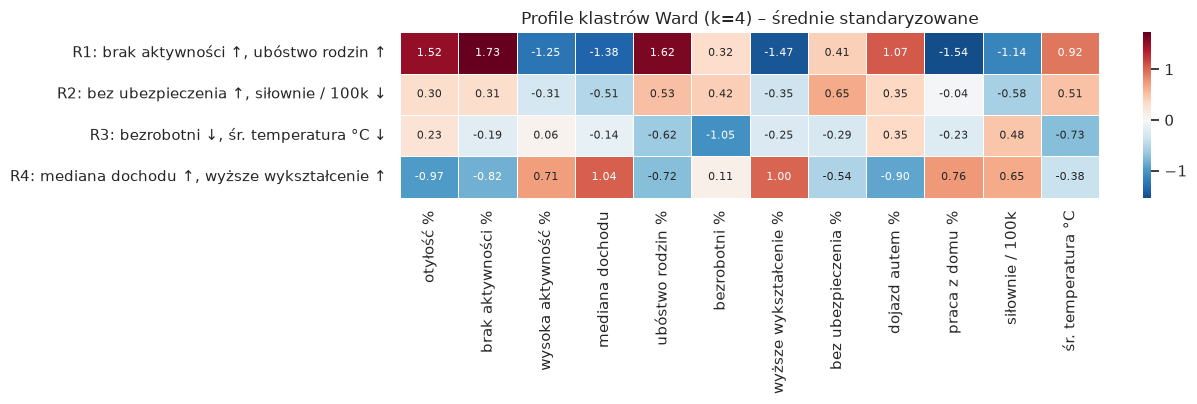

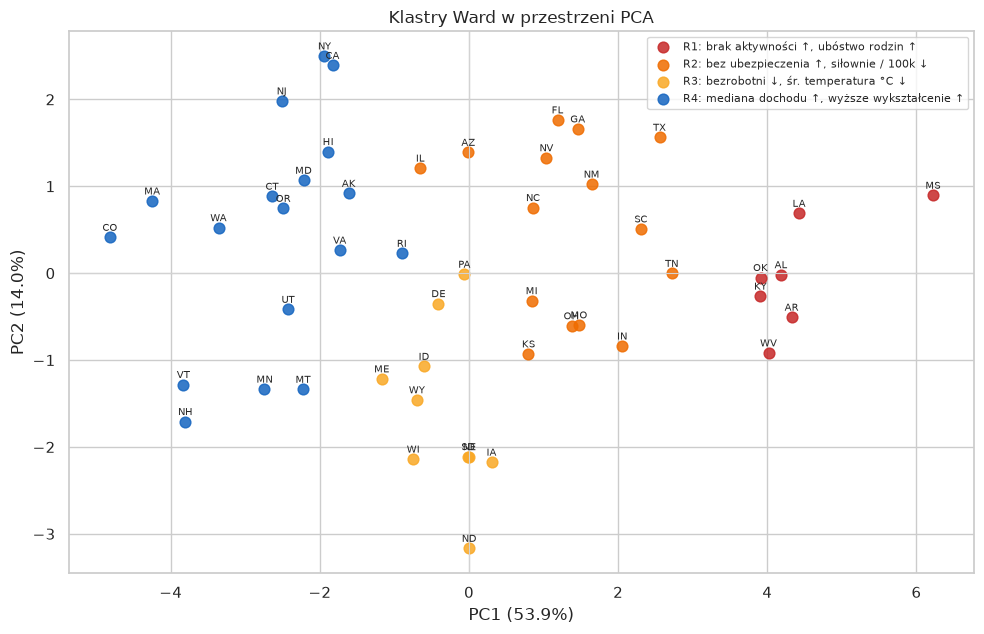

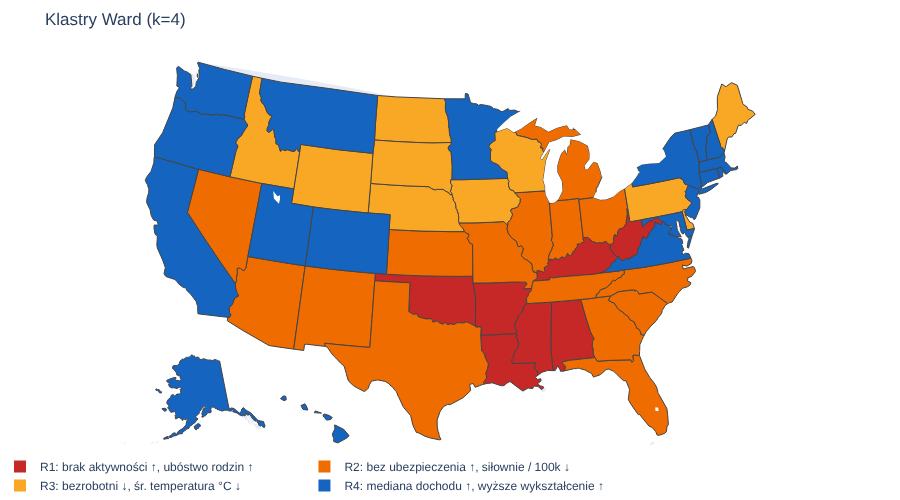

In [16]:
fig = plots.profile_heatmap(states, names_ward, CLUSTER_COLS, "Profile klastrów Ward (k=4) – średnie standaryzowane")
plots.save(fig, "10_profiles_ward")
plt.show()
fig = plots.pca_scatter(states, X2, explained, names_ward, plots.cluster_palette(names_ward), "Klastry Ward w przestrzeni PCA")
plt.show()
fig = plots.cluster_map(states, names_ward, "Klastry Ward (k=4)")
plots.save(fig, "map_ward")
fig.show()

### 7.2 Gaussian Mixture Model

In [17]:
print("silhouette vs k (covariance='full'):")
for k in range(2, 8):
    print(k, round(silhouette_score(X2, cl.gmm(X2, k, "full")), 3))
print("\nsilhouette vs covariance_type (k=5):")
for cov in ["full", "tied", "diag", "spherical"]:
    print(cov, round(silhouette_score(X2, cl.gmm(X2, 5, cov)), 3))

silhouette vs k (covariance='full'):


2 0.434


3 0.355


4 0.13


5 0.394


...

7 0.215

silhouette vs covariance_type (k=5):


full 0.394


tied 0.373


diag 0.378


spherical 0.38


In [18]:
labels_gmm = cl.gmm(X2, 5, "tied")
names_gmm = cl.cluster_names(states, labels_gmm, CLUSTER_COLS)
print(cl.scores(X2, labels_gmm))
for name, grp in states.groupby(names_gmm):
    print(f"{name} ({len(grp)}): {', '.join(grp['LocationAbbr'])}")

{'silhouette': 0.3732866453101338, 'davies_bouldin': 0.8685029596904299, 'n_clusters': 5}
R1: brak aktywności ↑, ubóstwo rodzin ↑ (8): AL, AR, KY, LA, MS, OK, TN, WV
R2: bezrobotni ↑, bez ubezpieczenia ↑ (12): AZ, DE, FL, GA, IL, NV, NM, NC, PA, RI, SC, TX
R3: bezrobotni ↓, śr. temperatura °C ↓ (13): ID, IN, IA, KS, ME, MI, MO, NE, ND, OH, SD, WI, WY
R4: bezrobotni ↓, brak aktywności ↓ (6): MN, MT, NH, UT, VT, VA
R5: dojazd autem ↓, mediana dochodu ↑ (11): AK, CA, CO, CT, HI, MD, MA, NJ, NY, OR, WA


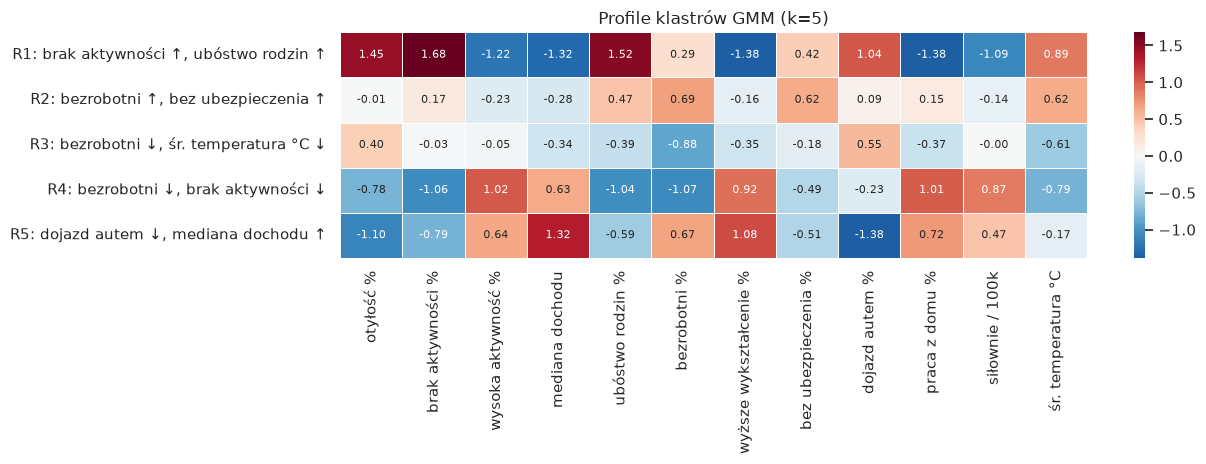

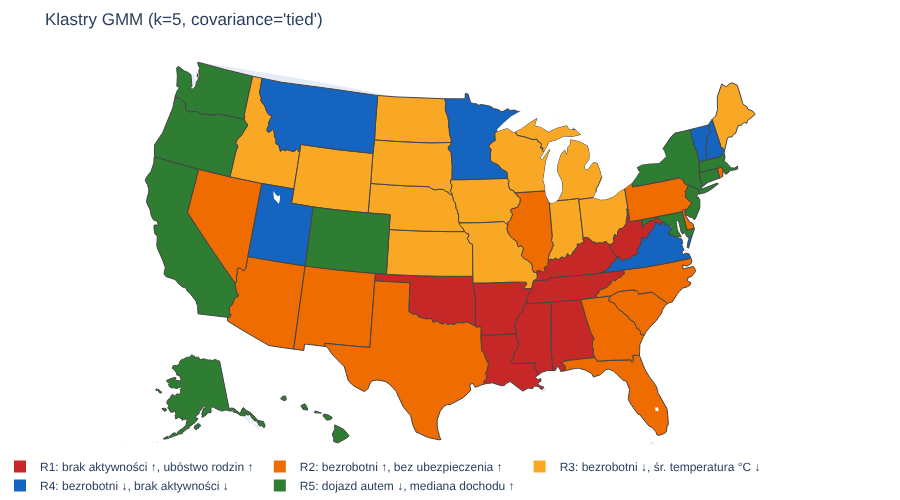

In [19]:
fig = plots.profile_heatmap(states, names_gmm, CLUSTER_COLS, "Profile klastrów GMM (k=5)")
plots.save(fig, "11_profiles_gmm")
plt.show()
fig = plots.cluster_map(states, names_gmm, "Klastry GMM (k=5, covariance='tied')")
plots.save(fig, "map_gmm")
fig.show()

### 7.3 K-Means

In [20]:
print("silhouette vs k:")
for k in range(2, 11):
    print(k, round(silhouette_score(X2, cl.kmeans(X2, k)), 3))
labels_km = cl.kmeans(X2, 5)
names_km = cl.cluster_names(states, labels_km, CLUSTER_COLS)
print(cl.scores(X2, labels_km))
for name, grp in states.groupby(names_km):
    print(f"{name} ({len(grp)}): {', '.join(grp['LocationAbbr'])}")

silhouette vs k:
2 0.443
3 0.391
4 0.416
5 0.429
6 0.434


7 0.449
8 0.451
9 0.449
10 0.437


{'silhouette': 0.42876502636905944, 'davies_bouldin': 0.7798856939037976, 'n_clusters': 5}
R1: brak aktywności ↑, ubóstwo rodzin ↑ (7): AL, AR, KY, LA, MS, OK, WV
R2: bez ubezpieczenia ↑, ubóstwo rodzin ↑ (12): FL, GA, IN, MI, MO, NV, NM, NC, OH, SC, TN, TX
R3: bezrobotni ↓, śr. temperatura °C ↓ (11): DE, ID, IA, KS, ME, NE, ND, PA, SD, WI, WY
R4: dojazd autem ↓, mediana dochodu ↑ (12): AK, AZ, CA, CT, HI, IL, MD, NJ, NY, OR, RI, VA
R5: brak aktywności ↓, praca z domu ↑ (8): CO, MA, MN, MT, NH, UT, VT, WA


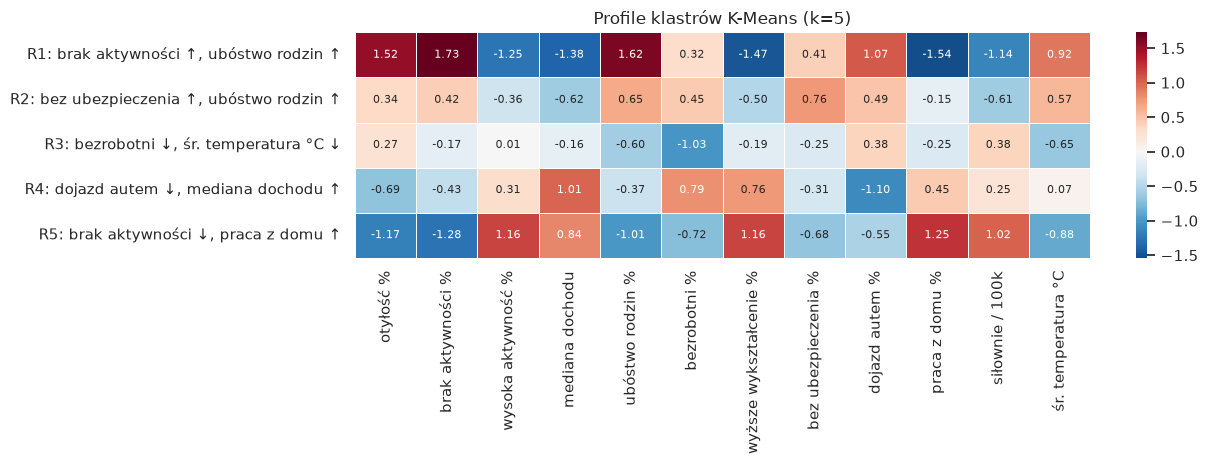

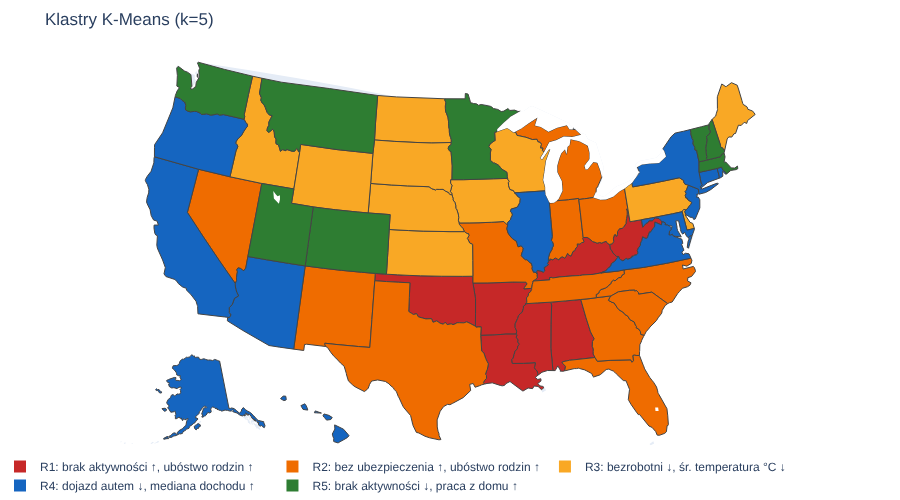

In [21]:
fig = plots.profile_heatmap(states, names_km, CLUSTER_COLS, "Profile klastrów K-Means (k=5)")
plots.save(fig, "12_profiles_kmeans")
plt.show()
fig = plots.cluster_map(states, names_km, "Klastry K-Means (k=5)")
plots.save(fig, "map_kmeans")
fig.show()

## 8. Porównanie metod

Silhouette (−1…1, wyżej = lepiej odseparowane klastry) i Davies-Bouldin (wyżej = gorzej) zależą od k, więc metody porównujemy też przy tym samym k=5.

In [22]:
solutions = {
    "Ward k=4": labels_ward,
    "Ward k=5": cl.hierarchical(X2, 5),
    "GMM k=5": labels_gmm,
    "K-Means k=5": labels_km,
}
pd.DataFrame({name: cl.scores(X2, lab) for name, lab in solutions.items()}).T.round(3)

,silhouette,davies_bouldin,n_clusters
Ward k=4,0.405,0.752,4.0
Ward k=5,0.406,0.815,5.0
GMM k=5,0.373,0.869,5.0
K-Means k=5,0.429,0.780,5.0


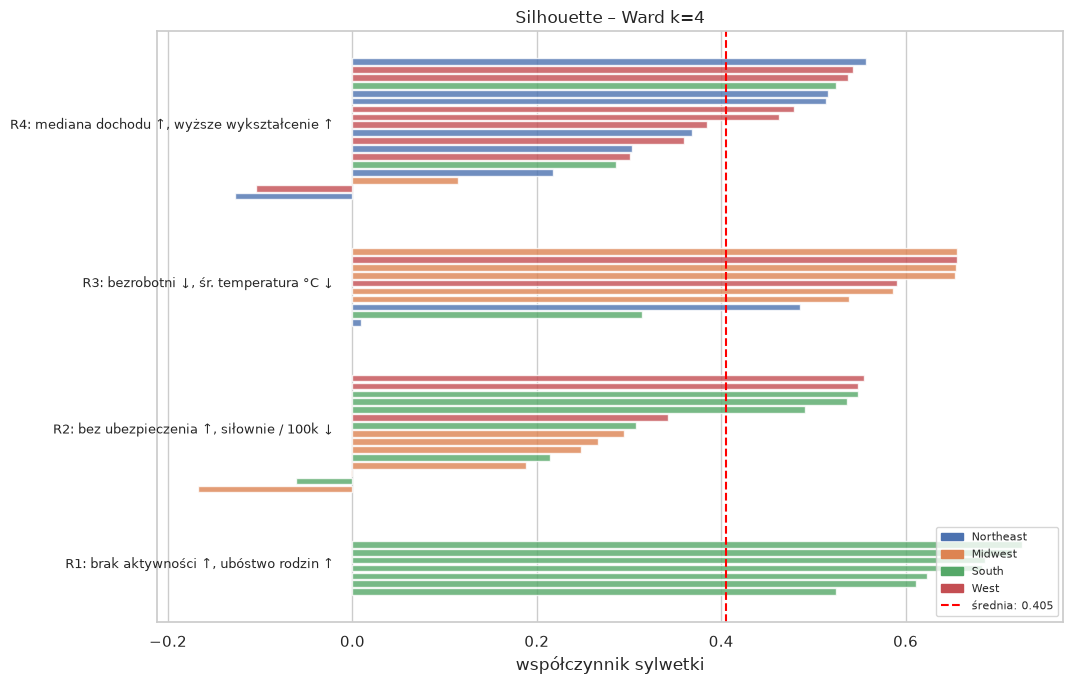

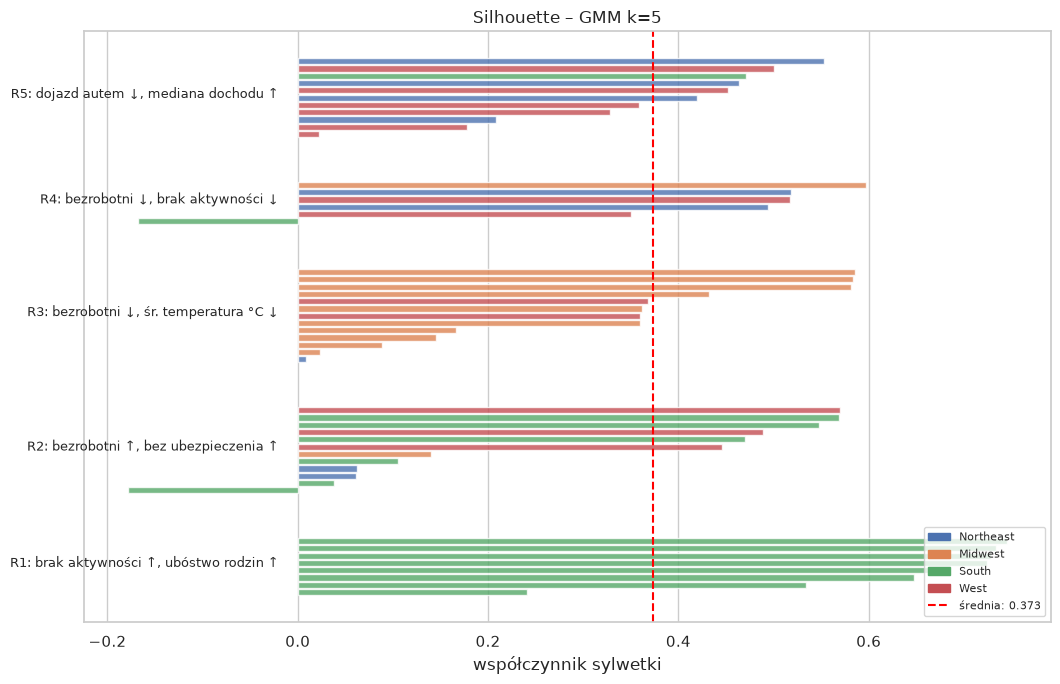

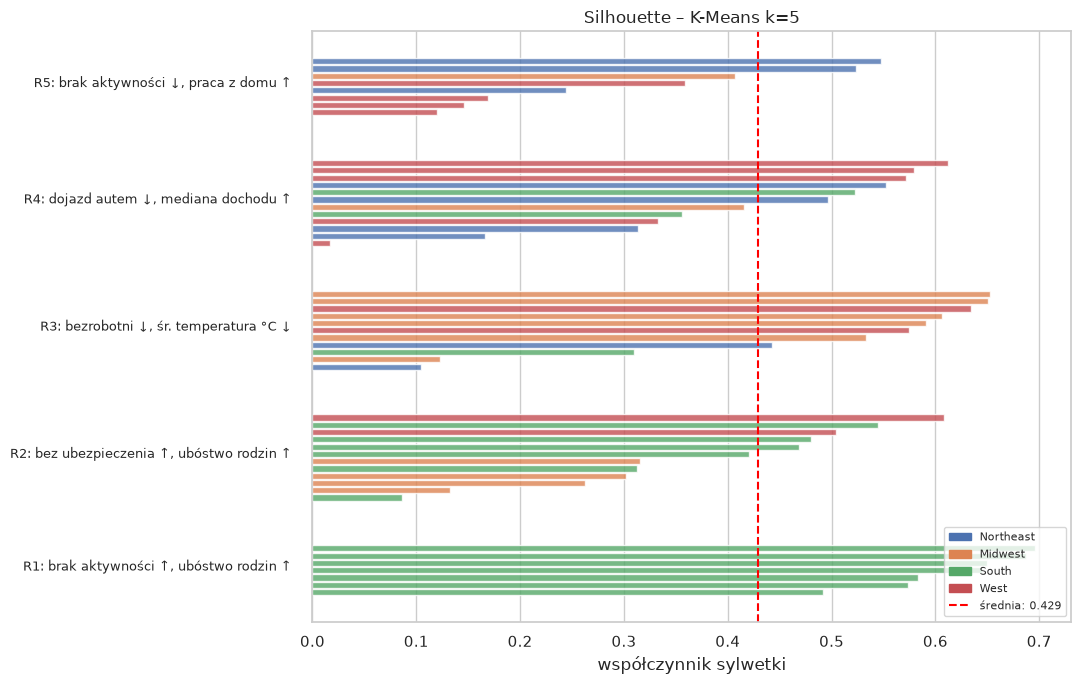

In [23]:
for name, lab, nm in [("Ward k=4", labels_ward, names_ward), ("GMM k=5", labels_gmm, names_gmm), ("K-Means k=5", labels_km, names_km)]:
    fig = plots.silhouette_plot(X2, lab, nm, states["Region"], f"Silhouette – {name}")
    plt.show()

## 9. Walidacja: czy te klastry są realne?

Sprawdzamy cztery rzeczy:
1. **wybór k** – silhouette w PC1–PC2 i w pełnej przestrzeni 12 zmiennych oraz BIC dla GMM (niżej = lepiej),
2. **zgodność metod** – Adjusted Rand Index (ARI: 1 = identyczny podział, 0 = zgodność losowa),
3. **wrażliwość na seed**,
4. **stabilność bootstrap** – losujemy stany ze zwracaniem, dopasowujemy od nowa skaler, PCA i model, porównujemy przypisania z wynikiem bazowym.

In [24]:
sweep = cl.k_sweep(X2, X_scaled)
bic_k1 = {
    "bic_gmm_pca2": GaussianMixture(1, covariance_type="tied").fit(X2).bic(X2),
    "bic_gmm_full": GaussianMixture(1, covariance_type="diag").fit(X_scaled).bic(X_scaled),
}
print("BIC dla k=1:", {k: round(v, 1) for k, v in bic_k1.items()})
sweep

BIC dla k=1: {'bic_gmm_pca2': 422.6, 'bic_gmm_full': 1796.6}


,sil_ward_pca2,sil_kmeans_pca2,sil_ward_full,sil_kmeans_full,sil_gmm_pca2,bic_gmm_pca2,bic_gmm_full
k,,,,,,,
2,0.401,0.443,0.271,0.294,0.319,429.591,1616.417
3,0.389,0.391,0.175,0.216,0.362,432.660,1593.327
4,0.405,0.416,0.195,0.233,0.409,441.329,1444.203
5,0.406,0.429,0.202,0.239,0.373,443.583,1489.025
6,0.404,0.434,0.196,0.244,0.355,452.852,1548.995
7,0.420,0.449,0.200,0.224,0.367,460.976,1537.238
8,0.408,0.451,0.195,0.201,0.401,464.865,1470.167


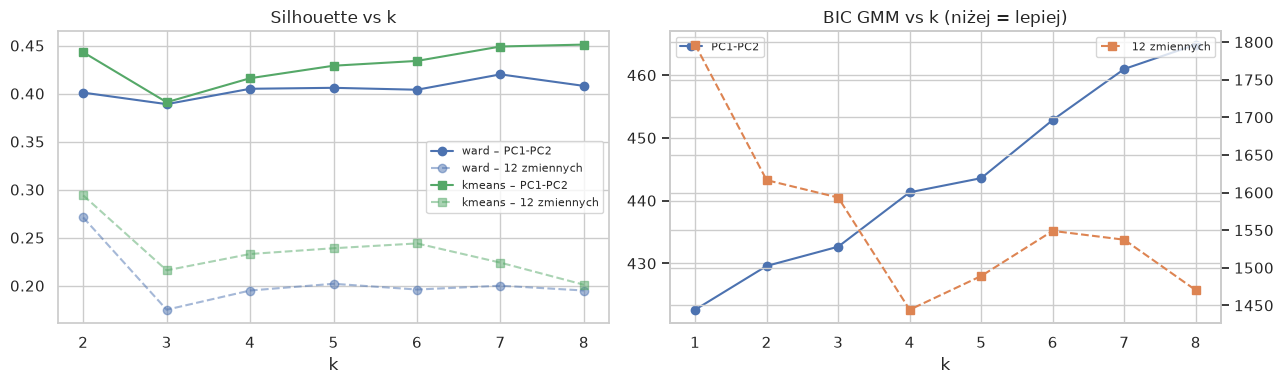

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col, style, color in [("sil_ward", "o", "C0"), ("sil_kmeans", "s", "C2")]:
    axes[0].plot(sweep.index, sweep[f"{col}_pca2"], style + "-", color=color, label=f"{col[4:]} – PC1-PC2")
    axes[0].plot(sweep.index, sweep[f"{col}_full"], style + "--", color=color, alpha=0.5, label=f"{col[4:]} – 12 zmiennych")
axes[0].set_title("Silhouette vs k")
axes[0].set_xlabel("k")
axes[0].legend(fontsize=8)
axes[1].plot([1] + list(sweep.index), [bic_k1["bic_gmm_pca2"]] + list(sweep["bic_gmm_pca2"]), "o-", label="PC1-PC2")
ax2 = axes[1].twinx()
ax2.plot([1] + list(sweep.index), [bic_k1["bic_gmm_full"]] + list(sweep["bic_gmm_full"]), "s--", color="C1", label="12 zmiennych")
axes[1].set_title("BIC GMM vs k (niżej = lepiej)")
axes[1].set_xlabel("k")
axes[1].legend(loc="upper left", fontsize=8)
ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plots.save(fig, "13_k_selection")
plt.show()

In [26]:
print("Silhouette tych samych podziałów policzony w pełnej przestrzeni 12 zmiennych:")
for name, lab in solutions.items():
    print(f"  {name}: {silhouette_score(X_scaled, lab):.3f}")
print("\nZgodność metod (ARI):")
cl.agreement({"Ward k=4": labels_ward, "Ward k=5": solutions["Ward k=5"], "GMM k=5": labels_gmm, "K-Means k=5": labels_km})

Silhouette tych samych podziałów policzony w pełnej przestrzeni 12 zmiennych:
  Ward k=4: 0.189
  Ward k=5: 0.183
  GMM k=5: 0.174
  K-Means k=5: 0.189

Zgodność metod (ARI):


,Ward k=4,Ward k=5,GMM k=5,K-Means k=5
Ward k=4,1.00,0.83,0.47,0.66
Ward k=5,0.83,1.00,0.48,0.78
GMM k=5,0.47,0.48,1.00,0.43
K-Means k=5,0.66,0.78,0.43,1.00


In [27]:
seeds = cl.seed_stability(X2, 5)
print("ARI względem seed=42 dla 100 innych seedów:")
seeds.describe().loc[["mean", "min", "50%"]].round(3)

ARI względem seed=42 dla 100 innych seedów:


,kmeans,gmm
mean,1.0,0.972
min,1.0,0.959
50%,1.0,0.959


In [28]:
boot = cl.bootstrap_stability(X_raw, {"ward": labels_ward, "gmm": labels_gmm, "kmeans": labels_km})
boot.describe().loc[["mean", "25%", "50%", "75%"]].round(3)

,ward,kmeans,gmm
mean,0.633,0.632,0.517
25%,0.514,0.538,0.388
50%,0.595,0.631,0.500
75%,0.761,0.744,0.643


In [29]:
# How often do the R1 states end up in one cluster when the analysis is re-run on bootstrap samples?
core = states.index[names_ward.str.startswith("R1")].to_numpy()
print("Rdzeń R1:", ", ".join(states.loc[core, "LocationAbbr"]))
rng = np.random.default_rng(0)
together = []
for b in range(100):
    idx = rng.choice(len(X_raw), len(X_raw), replace=True)
    _, Xb, _ = cl.fit_pca(X_raw[idx])
    km = cl.kmeans(Xb[:, :2], 5, seed=b)
    # labels of the core states via their first occurrence in the bootstrap sample
    pos = {i: np.where(idx == i)[0] for i in core}
    present = [km[p[0]] for p in pos.values() if len(p)]
    together.append(len(set(present)) == 1)
print(f"Wszystkie wylosowane stany z rdzenia w jednym klastrze K-Means: {np.mean(together):.0%} prób")

Rdzeń R1: AL, AR, KY, LA, MS, OK, WV


Wszystkie wylosowane stany z rdzenia w jednym klastrze K-Means: 99% prób


**Wnioski z walidacji**

- **Wybór k nie jest jednoznaczny.** W PC1–PC2 silhouette dla K-Means zmienia się łagodnie (0,39–0,45) bez wyraźnego maksimum. BIC dla GMM w PC1–PC2 jest najniższy dla **k=1**, czyli w tej przestrzeni nie ma wyraźnych skupisk, raczej ciągły gradient wzdłuż PC1. W pełnej przestrzeni 12 zmiennych BIC ma minimum przy **k=4** – to jedyny statystyczny argument za k=4.
- **Rzut na 2 składowe zawyża separację.** Te same podziały liczone w 12 wymiarach mają silhouette ok. 0,17–0,19, czyli słabą strukturę.
- **Ward k=4 i K-Means k=5 są zgodne** (ARI ok. 0,66; Ward k=5 vs K-Means 0,78). GMM odstaje (ARI < 0,5).
- **Seed:** K-Means przy `n_init=50` daje zawsze ten sam wynik. Wersja kursowa (`n_init=10`, seed 42) trafiała w gorsze lokalne minimum. GMM ma kilka rozwiązań o niemal identycznym log-likelihood – wynik z wersji kursowej (silhouette 0,426) był jednym z nich, rozwiązanie o najwyższej wiarygodności ma silhouette 0,37.
- **Bootstrap:** umiarkowana stabilność dla Ward i K-Means (mediana ARI ok. 0,6), słaba dla GMM (ok. 0,5).
- **Najpewniejszy wynik:** rdzeń 7 stanów wysokiego ryzyka (AL, AR, KY, LA, MS, OK, WV) jest identyczny w Ward i K-Means i trafia do jednego klastra w ok. 98% prób bootstrap.

## 10. Podsumowanie

1. **Stany różnią się głównie wzdłuż jednej osi** (PC1 = 54% wariancji): wykształcenie, dochód, praca z domu i siłownie vs otyłość, brak aktywności, ubóstwo i dojazd autem. Otyłość koreluje z dojazdem autem (ρ = 0,87), brakiem aktywności (0,76) i wykształceniem (−0,75). To korelacje między stanami (n = 50), nie efekty przyczynowe.
2. **Otyłość wzrosła w każdym regionie** w latach 2013–2023: o 3,5 pp (Northeast) do 6 pp (Midwest). Luka Południe vs reszta się utrzymuje.
3. **Jedyna naprawdę stabilna grupa** to 7 stanów wysokiego ryzyka (AL, AR, KY, LA, MS, OK, WV): najwyższa otyłość i brak aktywności, najniższe dochody i wykształcenie.
4. **Reszta podziału to raczej gradient niż wyraźne klastry.** Jako główny podział przyjmujemy **Ward k=4** (najlepszy kompromis stabilności i interpretowalności, wspierany przez BIC w pełnej przestrzeni):
   - R1: Deep South – wysokie ryzyko (7),
   - R2: Sun Belt i przemysłowy Midwest – podwyższone ryzyko, najwięcej nieubezpieczonych (15),
   - R3: chłodne, rolnicze stany o niskim bezrobociu (10),
   - R4: zamożne, wykształcone i aktywne stany (18).
   K-Means k=5 dodatkowo wydziela z R4 grupę najaktywniejszych stanów (CO, MA, MN, MT, NH, UT, VT, WA).
5. **GMM jest niestabilny** przy 50 obserwacjach (kilka równie dobrych rozwiązań), więc nie opieramy na nim wniosków.

**Ograniczenia:** 50 obserwacji; dane zagregowane do stanów (błąd ekologiczny); średnie łączą okres przed i po COVID; `HighActivity` mierzona co dwa lata; estymaty ACS 1-Year mają błąd próby, który tu pomijamy.